In [1]:
import pandas as pd
import scipy as sp
import numpy as np
from lightfm import cross_validation
from lightfm.evaluation import precision_at_k
from lightfm.evaluation import recall_at_k
from lightfm.evaluation import auc_score
from lightfm import LightFM
import matplotlib.pyplot as plt
import pickle
import os

**Loading in DHS presence/absence data**

In [2]:
#read in 733 sample x 3.5+ million DHS presence/absence matrix
dhs = pd.read_table('dat_bin_FDR01_hg38.txt.gz', header=None).T
dhs.shape

(733, 3591898)

In [3]:
data_coo = sp.sparse.coo_matrix(dhs.values)

**Loading in AverageOverBed output file**

In [283]:
GM06990_signal = pd.read_table('/home/ctrader/lightfm_data/out_ENCFF691MRD.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'mean'])

/home/ctrader/.conda/envs/lightfm/lib/python3.8/site-packages/IPython/core/interactiveshell.py:3441: DtypeWarning: Columns (0) have mixed types.Specify dtype option on import or set low_memory=False.
  exec(code_obj, self.user_global_ns, self.user_ns)


In [284]:
#reordering dataframe to match order of presence/absence matrix and DHS metadata dataframe

GM06990_signal[['name']] = GM06990_signal[['name']].astype(str)
GM06990_signal = GM06990_signal.set_index('name')
id_order = DHS_metadata['identifier'].to_list()
GM06990_signal = GM06990_signal.reindex(id_order)
GM06990_signal = GM06990_signal.reset_index()

#### **Loading in DHS signal matrix**

In [9]:
dhs_signal = pd.read_table('/home/ctrader/lightfm_data/dat_FDR01_hg38.txt')

In [19]:
dhs_signal_array = dhs_signal.T.to_numpy()

In [69]:
dhs_signal_array.mean(axis=0).shape

(3591897,)

**Top NMF biosample loadings**

In [170]:
top_biosamples = pd.read_table('/home/ctrader/lightfm_data/top15NMFBasisLoadings.txt')

**Previously trained (80/20 train/test split) model (k=10 components, epochs=30)**

In [5]:
pickle_in = open('/home/ctrader/Hold/DHS/DHS_model30.pickle', 'rb')
DHS_model30=pickle.load(pickle_in)

pickle_in = open('/home/ctrader/Hold/DHS/DHS_data30.pickle', 'rb')
DHS_data30=pickle.load(pickle_in)

In [35]:
#Precision and Recall @ k scores for DHS_data30.pickle and DHS_model30.pickle
with open('test_precision.txt') as f:
    test_precision = f.readlines()
print(test_precision)
with open('test_recall.txt') as f:
    test_recall = f.readlines()
print(test_recall)

print()
with open('train_precision.txt') as f:
    train_precision = f.readlines()
print(train_precision)
with open('train_recall.txt') as f:
    train_recall = f.readlines()
print(train_recall)

['Test Precision@[1, 10, 100, 1000, 10000] = [0.14324693, 0.14215554, 0.14713506, 0.15518418, 0.16692564]']
['Test Recall@[1, 10, 100, 1000, 10000] = [1.0259158846487058e-05, 0.00010940640060583263, 0.001110367405831415, 0.011533907822787908, 0.1206632319817199]']

['Train Precision@[1, 10, 100, 1000, 10000] = [0.82673943, 0.8308322, 0.8227558, 0.81127965, 0.7803032]']
['Train Recall@[1, 10, 100, 1000, 10000] = [1.4393877337148873e-05, 0.00014346459243132665, 0.001424563018470999, 0.014067948038458017, 0.13405498314124664]']


In [3]:
test_precision_e30_d10 = [0.14324693, 0.14215554, 0.14713506, 0.15518418, 0.16692564]
test_recall_e30_d10 = [1.0259158846487058e-05, 0.00010940640060583263, 0.001110367405831415, 0.011533907822787908, 0.1206632319817199]

train_precision_e30_d10 = [0.82673943, 0.8308322, 0.8227558, 0.81127965, 0.7803032]
train_recall_e30_d10 = [1.4393877337148873e-05, 0.00014346459243132665, 0.001424563018470999, 0.014067948038458017, 0.13405498314124664]

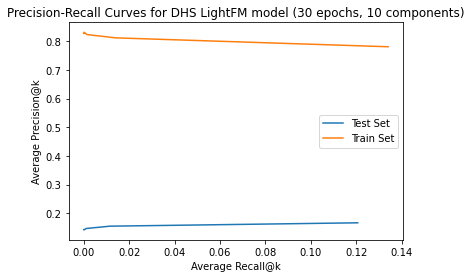

In [4]:
#Plot precision-recall curves for train and test data
fig = plt.figure()
fig.patch.set_facecolor('white')
plt.plot(test_recall_e30_d10, test_precision_e30_d10)
plt.plot(train_recall_e30_d10, train_precision_e30_d10)
plt.xlabel('Average Recall@k')
plt.ylabel('Average Precision@k')
plt.legend(['Test Set', 'Train Set'])
plt.title('Precision-Recall Curves for DHS LightFM model (30 epochs, 10 components)')
plt.savefig('PR_Curves_DHS_LightFM_CT20211004.jpeg')

In [290]:
#comparing recommendation scores between known and unknown positives

n_biosamples, n_DHSs = DHS_data30['train'].shape
biosample_name = 'GM06990'
biosample = list(biosample_df[biosample_df['Biosample name']==biosample_name]['library order'])[0] - 1
known_positives = [i for i, dhs_pos in enumerate(list(dhs.T[biosample])) if dhs_pos == 1]

not_known_ind = list(set(np.arange(n_DHSs)) - set(known_positives))
# nki_series = pd.Series(not_known_ind)

known_ind = list(set(known_positives))
# ki_series = pd.Series(not_known_ind)

filtered_scores_nki = DHS_model30.predict(biosample, np.array(not_known_ind))
filtered_scores_ki = DHS_model30.predict(biosample, np.array(known_ind))

# filtered_top_DHSs = [np.argsort(-filtered_scores)][0]
# top_rec_DHSs = nki_series[filtered_top_DHSs]

In [291]:
# boxplot_dict = {'Known Positives': list(filtered_scores_ki), 'Not Known Positives': list(filtered_scores_nki)}
boxplot_list = [list(filtered_scores_ki), list(filtered_scores_nki)]

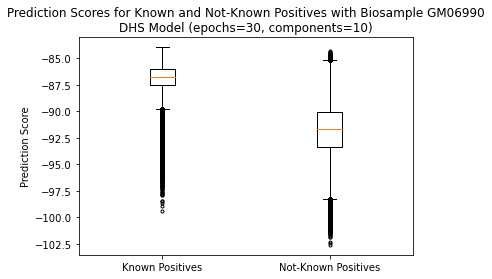

In [292]:
fig = plt.figure()
fig = fig.patch.set_facecolor('white')
fig = plt.boxplot(boxplot_list, sym='.')
fig = plt.xticks([1, 2], ['Known Positives', 'Not-Known Positives'])
fig = plt.ylabel('Prediction Score')
fig = plt.title('Prediction Scores for Known and Not-Known Positives with Biosample GM06990\nDHS Model (epochs=30, components=10)')

**Component precision recall curves for biosample GM06990**

In [275]:
rec_info = sample_recommendation(DHS_model30, DHS_data30, ['GM06990'], print_num=5)

Biosample: GM06990 (0)
   Number of Known DHSs: 82918

   Recommended DHS Locations:
      chr6:43383800-43384008, Component: Lymphoid, Number of Samples: 229
      chr22:20463632-20463840, Component: Lymphoid, Number of Samples: 77
      chr2:64283739-64283940, Component: Lymphoid, Number of Samples: 74
      chr15:89017645-89017840, Component: Tissue invariant, Number of Samples: 571
      chr1:225467176-225467360, Component: Lymphoid, Number of Samples: 115


In [276]:
comps = ['Tissue invariant','Stromal A', 'Primitive / embryonic', 'Stromal B', 'Lymphoid', 'Renal / cancer', 'Placental / trophoblast', 'Neural', 'Cardiac', 'Organ devel. / renal', 'Pulmonary devel.', 'Musculoskeletal', 'Digestive', 'Vascular / endothelial', 'Myeloid / erythroid', 'Cancer / epithelial']
color = ['grey', 'darkorchid', 'deepskyblue', 'slateblue', 'orange', 'slategrey', 'gold', 'royalblue', 'green', 'saddlebrown', 'chocolate', 'olivedrab', 'seagreen', 'darkolivegreen', 'red', 'darkblue']

In [277]:
all_comps_precision = []
all_comps_recall = []
for comp in comps:
    comp_precision = []
    comp_recall = []
    for k in [1, 10, 100, 1000, 10000, 100000, 1000000, len(rec_info[0][0])]:
        p, r = component_precision(rec_info[0], comp, k)
        comp_precision.append(p)
        comp_recall.append(r)
    all_comps_precision.append(comp_precision)
    all_comps_recall.append(comp_recall)

Text(0.5, 1.0, 'GM06990 Component PR Curve for DHS LightFM model (30 epochs, 10 components)')

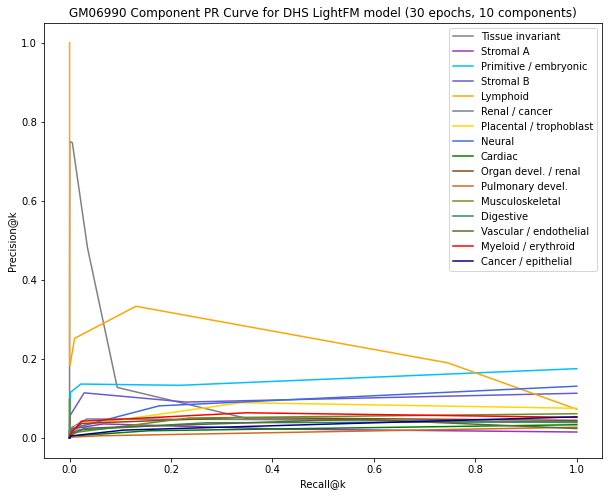

In [280]:
#Lymphoid component pr curve

fig = plt.figure(figsize=(10,8))
fig.patch.set_facecolor('white')
for i in range(len(comps)):
    plt.plot(all_comps_recall[i], all_comps_precision[i], color=color[i])
plt.xlabel('Recall@k')
plt.ylabel('Precision@k')
# plt.xscale('log')
plt.legend(comps)
plt.title('GM06990 Component PR Curve for DHS LightFM model (30 epochs, 10 components)')

**Component precision recall curves for top biosamples of each component**

In [171]:
biosamples = []
biosample_names = []
for comp in comps:
    biosamples.append(list(df[df['Altius Biosample ID'] == list(top_biosamples[comp])[0]].index)[0])
    biosample_names.append(list(df[df['Altius Biosample ID'] == list(top_biosamples[comp])[0]]['Biosample name'])[0])
    biosamples.append(list(df[df['Altius Biosample ID'] == list(top_biosamples[comp])[-1]].index)[0])
    biosample_names.append(list(df[df['Altius Biosample ID'] == list(top_biosamples[comp])[-1]]['Biosample name'])[0])
#     biosamples.append(list(top_biosamples[comp])[0])
#     biosamples.append(list(top_biosamples[comp])[-1])

In [172]:
top_biosample_precision = []
top_biosample_recall = []
for sample in biosamples:
    l = []
    l.append(sample)
    rec_info = sample_recommendation(DHS_model30, DHS_data30, l, print_num=0)
    all_comps_precision = []
    all_comps_recall = []
    for comp in comps:
        comp_precision = []
        comp_recall = []
        for k in [1, 10, 100, 1000, 10000, 100000, 1000000, len(rec_info[0][0])]:
            p, r = component_precision(rec_info[0], comp, k)
            comp_precision.append(p)
            comp_recall.append(r)
        all_comps_precision.append(comp_precision)
        all_comps_recall.append(comp_recall)
    top_biosample_precision.append(all_comps_precision)
    top_biosample_recall.append(all_comps_recall)

Biosample: 262 (262)
   Number of Known DHSs: 45431

   Recommended DHS Locations:
Biosample: 227 (227)
   Number of Known DHSs: 47071

   Recommended DHS Locations:
Biosample: 444 (444)
   Number of Known DHSs: 100575

   Recommended DHS Locations:
Biosample: 125 (125)
   Number of Known DHSs: 89913

   Recommended DHS Locations:
Biosample: 44 (44)
   Number of Known DHSs: 314868

   Recommended DHS Locations:
Biosample: 698 (698)
   Number of Known DHSs: 113531

   Recommended DHS Locations:
Biosample: 618 (618)
   Number of Known DHSs: 323984

   Recommended DHS Locations:
Biosample: 71 (71)
   Number of Known DHSs: 282010

   Recommended DHS Locations:
Biosample: 272 (272)
   Number of Known DHSs: 138520

   Recommended DHS Locations:
Biosample: 156 (156)
   Number of Known DHSs: 91014

   Recommended DHS Locations:
Biosample: 678 (678)
   Number of Known DHSs: 204786

   Recommended DHS Locations:
Biosample: 645 (645)
   Number of Known DHSs: 89732

   Recommended DHS Locations:
B

Text(0, 0.5, 'Precision@k')

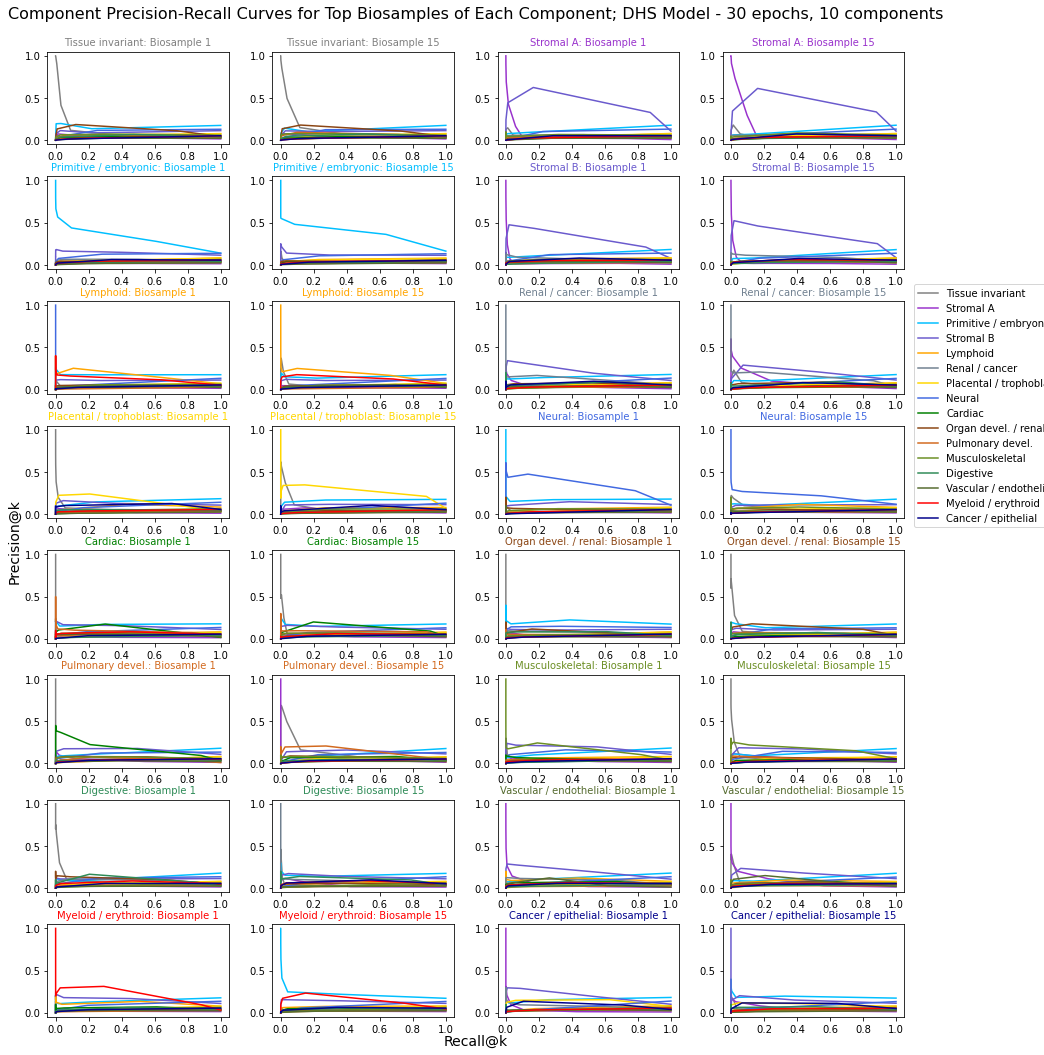

In [173]:
fig, axes = plt.subplots(nrows=8, ncols=4, figsize=(14,14))
fig.tight_layout()
fig.patch.set_facecolor('white')

for ax, ind in zip(fig.axes, range(32)):
    for i in range(len(comps)):
        ax.plot(top_biosample_recall[ind][i], top_biosample_precision[ind][i], color=color[i])
    if ind % 2 == 0:
        biosample_rank = '1'
    else:
        biosample_rank = '15'
    component = comps[ind // 2]
    ax.set_title(component + ': Biosample ' + biosample_rank, fontsize=10, color=color[ind//2])


fig.subplots_adjust(right=0.89)
# lines, labels = fig.axes[-1].get_legend_handles_labels()
fig.legend(comps, loc = (0.875, 0.5))
# print(lines)
fig.suptitle('Component Precision-Recall Curves for Top Biosamples of Each Component; DHS Model - 30 epochs, 10 components', fontsize=16, x=0.465, y=1.03)
# fig.xlabel('Recall@k')
# fig.ylabel('Precision@k')
fig.text(0.465, 0, 'Recall@k', ha='center', fontsize=14)
fig.text(0, 0.5, 'Precision@k', va='center', rotation='vertical', fontsize=14)

**Second Model (k=16 components, epochs=15) with Train/Test split of 80/20**

In [38]:
#splitting data into train and test
(train, test) = cross_validation.random_train_test_split(data_coo, test_percentage=0.2, random_state=None)
data = {'train': train, 'test': test}

In [39]:
#creating model
model_e15_d16 = LightFM(no_components=16, loss='warp')

In [40]:
#training model
model_e15_d16.fit(data['train'], epochs=15, num_threads=2)

In [41]:
pickle_out_model = open('/home/ctrader/Hold/DHS/DHS_model_e15_d16.pickle', 'wb')
pickle.dump(model_e15_d16, pickle_out_model)
pickle_out_model.close()

pickle_out_data = open('/home/ctrader/Hold/DHS/DHS_data_e15_d16.pickle', 'wb')
pickle.dump(data, pickle_out_data)
pickle_out_data.close()

In [33]:
pickle_in = open('/home/ctrader/Hold/DHS/DHS_model_e15_d16.pickle', 'rb')
DHS_model_e15_d16=pickle.load(pickle_in)

pickle_in = open('/home/ctrader/Hold/DHS/DHS_data_e15_d16.pickle', 'rb')
DHS_data_e15_d16=pickle.load(pickle_in)

In [7]:
#Calculating precision and recall for test set
test_precision_list_top = []
test_recall_list_top = []
for k in [1, 10, 100, 1000, 10000]:
    print(k)
    num = []
    n_known_pos = []
    for biosample in range(733):
        if biosample % 100 == 0:
            print(biosample, '/', n_biosamples)
        scores = model.predict(biosample, np.arange(n_dhs)) 
        top_DHSs = [np.argsort(-scores)][0][0:k]
        known_pos = [i for i, dhs_pos in enumerate(np.squeeze(np.asarray(test_dense[biosample]))) if dhs_pos == 1]
        top_in_known = len([i for i in known_pos if i in top_DHSs])
        num.append(top_in_known)
        n_known_pos.append(len(known_pos))
            
    num = np.array(num)
    precision = (num/k).mean()
    recall = (num/n_known_pos).mean()
    print(precision)
    print(recall)
    test_precision_list_top.append(precision)
    test_recall_list_top.append(recall)

1
0 / 733
100 / 733
200 / 733
300 / 733
400 / 733
500 / 733
600 / 733
700 / 733
0.15006821282401092
1.1607047374607913e-05
10
0 / 733
100 / 733
200 / 733
300 / 733
400 / 733
500 / 733
600 / 733
700 / 733
0.1281036834924966
0.00010259687720124615
100
0 / 733
100 / 733
200 / 733
300 / 733
400 / 733
500 / 733
600 / 733
700 / 733
0.13607094133697137
0.0010623306048059748
1000
0 / 733
100 / 733
200 / 733
300 / 733
400 / 733
500 / 733
600 / 733
700 / 733
0.1459781718963165
0.011175172057686316
10000
0 / 733
100 / 733
200 / 733
300 / 733
400 / 733
500 / 733
600 / 733
700 / 733
0.1600350613915416
0.11879437216194183


In [8]:
#Calculating precision and recall for train set
train_precision_list_top = []
train_recall_list_top = []
for k in [1, 10, 100, 1000, 10000]:
    print(k)
    num = []
    n_known_pos = []
    for biosample in range(733):
        if biosample % 100 == 0:
            print(biosample, '/', n_biosamples)
        scores = model.predict(biosample, np.arange(n_dhs)) 
        top_DHSs = [np.argsort(-scores)][0][0:k]
        known_pos = [i for i, dhs_pos in enumerate(np.squeeze(np.asarray(train_dense[biosample]))) if dhs_pos == 1]
        top_in_known = len([i for i in known_pos if i in top_DHSs])
        num.append(top_in_known)
        n_known_pos.append(len(known_pos))
            
    num = np.array(num)
    precision = (num/k).mean()
    recall = (num/n_known_pos).mean()
    print(precision)
    print(recall)
    train_precision_list_top.append(precision)
    train_recall_list_top.append(recall)

1
0 / 733
100 / 733
200 / 733
300 / 733
400 / 733
500 / 733
600 / 733
700 / 733
0.8362892223738063
1.4589387054741919e-05
10
0 / 733
100 / 733
200 / 733
300 / 733
400 / 733
500 / 733
600 / 733
700 / 733
0.8575716234652115
0.000148460313560959
100
0 / 733
100 / 733
200 / 733
300 / 733
400 / 733
500 / 733
600 / 733
700 / 733
0.8448158253751705
0.0014616834782521981
1000
0 / 733
100 / 733
200 / 733
300 / 733
400 / 733
500 / 733
600 / 733
700 / 733
0.8309222373806274
0.014391052828586376
10000
0 / 733
100 / 733
200 / 733
300 / 733
400 / 733
500 / 733
600 / 733
700 / 733
0.7954879945429739
0.13631831128367736


In [3]:
model_e15_d16_test_precision = [0.15006821282401092, 0.1281036834924966, 0.13607094133697137, 0.1459781718963165, 0.1600350613915416]
model_e15_d16_test_recall = [1.1607047374607913e-05, 0.00010259687720124615, 0.0010623306048059748, 0.011175172057686316, 0.11879437216194183]

model_e15_d16_train_precision = [0.8362892223738063, 0.8575716234652115, 0.8448158253751705, 0.8309222373806274, 0.7954879945429739]
model_e15_d16_train_recall = [1.4589387054741919e-05, 0.000148460313560959, 0.0014616834782521981, 0.014391052828586376, 0.13631831128367736]

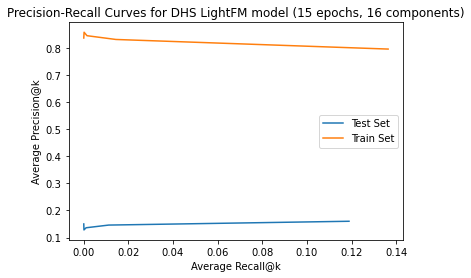

In [4]:
#Plot precision-recall curves for train and test data (15 epochs, 16 dimensions)

fig = plt.figure()
fig.patch.set_facecolor('white')
plt.plot(model_e15_d16_test_recall, model_e15_d16_test_precision)
plt.plot(model_e15_d16_train_recall, model_e15_d16_train_precision)
plt.xlabel('Average Recall@k')
plt.ylabel('Average Precision@k')
plt.legend(['Test Set', 'Train Set']) #, 'Train Set'
plt.title('Precision-Recall Curves for DHS LightFM model (15 epochs, 16 components)')
plt.savefig('PR_Curves_DHS_LightFM_CT20211005.jpeg')

In [ ]:
sample_recommendation(DHS_model_e15_d16, DHS_data_e15_d16, ['GM06990'])

Biosample: GM06990 (0)
   Number of Known DHSs: 82918

   Recommended DHS Locations:
      chr10:41860220-41860380, Component: Tissue invariant, Number of Samples: 726
      chr20:50958700-50958900, Component: Tissue invariant, Number of Samples: 644
      chr6:30556860-30557080, Component: Tissue invariant, Number of Samples: 683
      chr1:86915341-86915607, Component: Tissue invariant, Number of Samples: 311
      chr16:34582143-34582318, Component: Tissue invariant, Number of Samples: 713

Number of known positive recs before 5 new recs: 143


**Creating a simple model (with k=1 components and epochs=1) and training the model on 80/20 train/test split**

In [20]:
#creating simple model
model_e1_d1 = LightFM(no_components=1, loss='warp')

In [21]:
#training simple model
model_e1_d1.fit(data['train'], epochs=1, num_threads=2)

In [46]:
pickle_out_model = open('/home/ctrader/Hold/DHS/DHS_model_e1_d1.pickle', 'wb')
pickle.dump(model_e1_d1, pickle_out_model)
pickle_out_model.close()

pickle_out_data = open('/home/ctrader/Hold/DHS/DHS_data_e1_d1.pickle', 'wb')
pickle.dump(data, pickle_out_data)
pickle_out_data.close()

In [307]:
sample_recommendation(model_e15_d16_reg0001, data_e15_d16_reg0001, ['GM06990'])

NameError: name 'model_e15_d16_reg0001' is not defined

In [38]:
train_dense = data['train'].todense()
test_dense = data['test'].todense()

In [43]:
#Making sure the external precision recall function I wrote (see precision_recall_function_DHS_test_CT20211005.py)
#matches the function written in this notebook
test_precision_e1_d1, test_recall_e1_d1 = precision_recall(test_dense, model_e1_d1)

k = 1
0 / 733 biosamples done
100 / 733 biosamples done
200 / 733 biosamples done
300 / 733 biosamples done
400 / 733 biosamples done
500 / 733 biosamples done
600 / 733 biosamples done
700 / 733 biosamples done
precision@1 = 0.1937244201909959
recall@1 = 1.3154694509024866e-05
k = 10
0 / 733 biosamples done
100 / 733 biosamples done
200 / 733 biosamples done
300 / 733 biosamples done
400 / 733 biosamples done
500 / 733 biosamples done
600 / 733 biosamples done
700 / 733 biosamples done
precision@10 = 0.19276944065484314
recall@10 = 0.0001351832908074869
k = 100
0 / 733 biosamples done
100 / 733 biosamples done
200 / 733 biosamples done
300 / 733 biosamples done
400 / 733 biosamples done
500 / 733 biosamples done
600 / 733 biosamples done
700 / 733 biosamples done
precision@100 = 0.19395634379263305
recall@100 = 0.0013733302147636588
k = 1000
0 / 733 biosamples done
100 / 733 biosamples done
200 / 733 biosamples done
300 / 733 biosamples done
400 / 733 biosamples done
500 / 733 biosamp

In [53]:
#Precision and Recall @ k scores for DHS_moodel_e1_d1 obtained from precision_recall_function_DHS_test_CT20211005.py
with open('DHS_model_e1_d1_test_precision_recall.txt') as f:
    test_precision_recall = f.readlines()
print(test_precision_recall)
with open('DHS_model_e1_d1_train_precision_recall.txt') as f:
    train_precision_recall = f.readlines()
print(train_precision_recall)

['Test Precision@[1, 10, 100, 1000, 10000] = [0.1937244201909959, 0.19276944065484314, 0.19395634379263305, 0.18997407912687586, 0.1798338335607094] \n', 'Test Recall@[1, 10, 100, 1000, 10000] = [1.3154694509024866e-05, 0.0001351832908074869, 0.0013733302147636588, 0.013248996263552942, 0.12206706241599925]']
['Train Precision@[1, 10, 100, 1000, 10000] = [0.7830832196452933, 0.7879945429740791, 0.7856616643929059, 0.7712223738062757, 0.7233263301500683] \n', 'Train Recall@[1, 10, 100, 1000, 10000] = [1.389557222091376e-05, 0.00013873996087605507, 0.0013754109708364738, 0.013403138149935887, 0.12262116386584553]']


In [303]:
model_e1_d1_test_precision = [0.1937244201909959, 0.19276944065484314, 0.19395634379263305, 0.18997407912687586, 0.1798338335607094]
model_e1_d1_test_recall = [1.3154694509024866e-05, 0.0001351832908074869, 0.0013733302147636588, 0.013248996263552942, 0.12206706241599925]

model_e1_d1_train_precision = [0.7830832196452933, 0.7879945429740791, 0.7856616643929059, 0.7712223738062757, 0.7233263301500683]
model_e1_d1_train_recall = [1.389557222091376e-05, 0.00013873996087605507, 0.0013754109708364738, 0.013403138149935887, 0.12262116386584553]

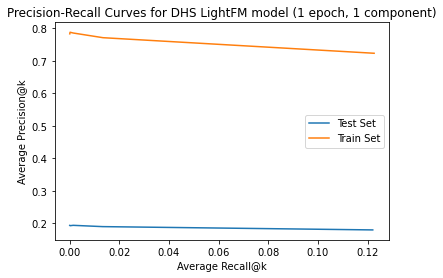

In [56]:
#Plot precision-recall curves for train and test data (1 epochs, 1 dimensions)
plt.plot(model_e1_d1_test_recall, model_e1_d1_test_precision)
plt.plot(model_e1_d1_train_recall, model_e1_d1_train_precision)
plt.xlabel('Average Recall@k')
plt.ylabel('Average Precision@k')
plt.legend(['Test Set', 'Train Set'])
plt.title('Precision-Recall Curves for DHS LightFM model (1 epoch, 1 component)')
plt.savefig('PR_Curves_DHS_model_e1_d1_LightFM_CT20211005.jpeg')

**Training k=1 component, epochs=1 model on 50/50 train/test split data and comparing to same model trained on 80/20 train/test split data**

In [59]:
#50/50 train test split to test precision values between train and test datasets
(train, test) = cross_validation.random_train_test_split(data_coo, test_percentage=0.5, random_state=None)
data_50_50 = {'train': train, 'test': test}

In [60]:
#creating model
model_e1_d1_tts50 = LightFM(no_components=1, loss='warp')
#training model
model_e1_d1_tts50.fit(data_50_50['train'], epochs=1, num_threads=2)

In [61]:
pickle_out_model = open('/home/ctrader/Hold/DHS/DHS_model_e1_d1_tts50.pickle', 'wb')
pickle.dump(model_e1_d1_tts50, pickle_out_model)
pickle_out_model.close()

pickle_out_data = open('/home/ctrader/Hold/DHS/DHS_data_e1_d1_tts50.pickle', 'wb')
pickle.dump(data_50_50, pickle_out_data)
pickle_out_data.close()

In [63]:
#Precision and Recall @ k scores for DHS_moodel_e1_d1
with open('DHS_model_e1_d1_tts50_test_precision_recall.txt') as f:
    test_precision_recall = f.readlines()
print(test_precision_recall)
print()
with open('DHS_model_e1_d1_tts50_train_precision_recall.txt') as f:
    train_precision_recall = f.readlines()
print(train_precision_recall)

['Test Precision@[1, 10, 100, 1000, 10000] = [0.4147339699863574, 0.46439290586630283, 0.4684720327421555, 0.46423874488403827, 0.43699072305593445] \n', 'Test Recall@[1, 10, 100, 1000, 10000] = [1.1213092077233432e-05, 0.0001286555667116926, 0.0013036450610856877, 0.012825850763550774, 0.11754179273357541]']

['Train Precision@[1, 10, 100, 1000, 10000] = [0.4965893587994543, 0.49863574351978174, 0.48964529331514334, 0.4750723055934516, 0.4418092769440655] \n', 'Train Recall@[1, 10, 100, 1000, 10000] = [1.3757628389097575e-05, 0.0001397973858022772, 0.0013618001676355498, 0.013083964610770561, 0.11877394989436554]']


In [302]:
model_e1_d1_tts50_test_precision = [0.4147339699863574, 0.46439290586630283, 0.4684720327421555, 0.46423874488403827, 0.43699072305593445]
model_e1_d1_tts50_test_recall = [1.1213092077233432e-05, 0.0001286555667116926, 0.0013036450610856877, 0.012825850763550774, 0.11754179273357541]

model_e1_d1_tts50_train_precision = [0.4965893587994543, 0.49863574351978174, 0.48964529331514334, 0.4750723055934516, 0.4418092769440655]
model_e1_d1_tts50_train_recall = [1.3757628389097575e-05, 0.0001397973858022772, 0.0013618001676355498, 0.013083964610770561, 0.11877394989436554]

Text(0.5, 1.0, 'Precision-Recall Curves for DHS LightFM model (1 epoch, 1 component)')

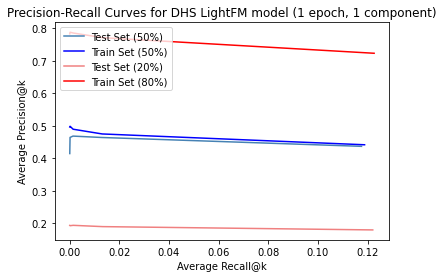

In [304]:
#Plot precision-recall curves for train and test data (1 epochs, 1 dimensions)
fig = plt.figure()
fig.patch.set_facecolor('white')
plt.plot(model_e1_d1_tts50_test_recall, model_e1_d1_tts50_test_precision, color='steelblue')
plt.plot(model_e1_d1_tts50_train_recall, model_e1_d1_tts50_train_precision, color='blue')
plt.plot(model_e1_d1_test_recall, model_e1_d1_test_precision, color='lightcoral')
plt.plot(model_e1_d1_train_recall, model_e1_d1_train_precision, color='red')
plt.xlabel('Average Recall@k')
plt.ylabel('Average Precision@k')
plt.legend(['Test Set (50%)', 'Train Set (50%)', 'Test Set (20%)', 'Train Set (80%)'], 
           loc='upper left')
plt.title('Precision-Recall Curves for DHS LightFM model (1 epoch, 1 component)')
# plt.savefig('PR_Curves_DHS_model_e1_d1_LightFM_CT20211005.jpeg')

**Training k=16 components, epochs=15 model with 50/50 train/test split**

In [100]:
#creating model with 50/50 tts 
model_e15_d16_tts50 = LightFM(no_components=16, loss='warp')
#training model
model_e15_d16_tts50.fit(data_50_50['train'], epochs=15, num_threads=2)

In [101]:
pickle_out_model = open('/home/ctrader/Hold/DHS/DHS_model_e15_d16_tts50.pickle', 'wb')
pickle.dump(model_e15_d16_tts50, pickle_out_model)
pickle_out_model.close()

pickle_out_data = open('/home/ctrader/Hold/DHS/DHS_data_e15_d16_tts50.pickle', 'wb')
pickle.dump(data_50_50, pickle_out_data)
pickle_out_data.close()

In [ ]:
#Precision and Recall @ k scores for DHS_model_e15_d16_tts50
with open('DHS_model_e15_d16_tts50_test_precision_recall.txt') as f:
    test_precision_recall = f.readlines()
print(test_precision_recall)
print()
with open('DHS_model_e15_d16_tts50_train_precision_recall.txt') as f:
    train_precision_recall = f.readlines()
print(train_precision_recall)

 **Adjusting alpha regularization values for model 2 (k=16 components, epochs=15) to 0.05**

In [104]:
#80/20 train test split to test precision values between train and test datasets
(train, test) = cross_validation.random_train_test_split(data_coo, test_percentage=0.2, random_state=None)
data_80_20 = {'train': train, 'test': test}
#creating model with L2 regularization set to 0.05, k=16 components
model_e15_d16_reg05 = LightFM(no_components=16, loss='warp', item_alpha=0.05, user_alpha=0.05)
#training model
model_e15_d16_reg05.fit(data_80_20['train'], epochs=15, num_threads=2)

In [105]:
pickle_out_model = open('/home/ctrader/Hold/DHS/DHS_model_e15_d16_reg05.pickle', 'wb')
pickle.dump(model_e15_d16_reg05, pickle_out_model)
pickle_out_model.close()

pickle_out_data = open('/home/ctrader/Hold/DHS/DHS_data_e15_d16_reg05.pickle', 'wb')
pickle.dump(data_80_20, pickle_out_data)
pickle_out_data.close()

**Adjusting alpha regularization values for model (k=16 components, epochs=15, LR=0.01) to 0.001**

In [12]:
#80/20 train test split to test precision values between train and test datasets
(train, test) = cross_validation.random_train_test_split(data_coo, test_percentage=0.2, random_state=None)
data_80_20 = {'train': train, 'test': test}
#creating model with L2 regularization set to 0.001, k=16 components, learning rate of 0.01
model_e15_d16_reg001_lr01 = LightFM(no_components=16, loss='warp', item_alpha=0.001, user_alpha=0.001, learning_rate=0.01)
#training model
model_e15_d16_reg001_lr01.fit(data_80_20['train'], epochs=15, num_threads=2)

In [13]:
pickle_out_model = open('/home/ctrader/Hold/DHS/DHS_model_e15_d16_reg001_lr01.pickle', 'wb')
pickle.dump(model_e15_d16_reg001_lr01, pickle_out_model)
pickle_out_model.close()

pickle_out_data = open('/home/ctrader/Hold/DHS/DHS_data_e15_d16_reg001_lr01.pickle', 'wb')
pickle.dump(data_80_20, pickle_out_data)
pickle_out_data.close()

In [9]:
pickle_in = open('/home/ctrader/Hold/DHS/DHS_model_e15_d16_reg001_lr01.pickle', 'rb')
model_e15_d16_reg001_lr01=pickle.load(pickle_in)

pickle_in = open('/home/ctrader/Hold/DHS/DHS_data_e15_d16_reg001_lr01.pickle', 'rb')
data_e15_d16_reg001_lr01=pickle.load(pickle_in)

In [4]:
user_b, user_e = model_e15_d16_reg001_lr01.get_user_representations()
print(user_e)
item_b, item_e = model_e15_d16_reg001_lr01.get_item_representations()
print(item_e)

[[ 0. -0. -0. ...  0.  0. -0.]
 [ 0. -0. -0. ...  0.  0. -0.]
 [-0. -0. -0. ... -0.  0.  0.]
 ...
 [ 0. -0.  0. ...  0.  0. -0.]
 [-0.  0.  0. ... -0. -0.  0.]
 [-0.  0.  0. ... -0. -0.  0.]]
[[ 0.  0.  0. ...  0.  0.  0.]
 [ 0. -0. -0. ...  0.  0. -0.]
 [ 0.  0.  0. ...  0.  0.  0.]
 ...
 [ 0.  0.  0. ...  0.  0.  0.]
 [ 0.  0.  0. ...  0.  0.  0.]
 [ 0.  0.  0. ...  0.  0.  0.]]


In [10]:
# test_precision_e15_d16_reg001_lr01, test_recall_e15_d16_reg001_lr01 = precision_recall_full(model_e15_d16_reg001_lr01, data_e15_d16_reg001_lr01['test'], [1, 10, 100, 1000, 10000])
# train_precision_e15_d16_reg001_lr01, train_recall_e15_d16_reg001_lr01 = precision_recall_full(model_e15_d16_reg001_lr01, data_e15_d16_reg001_lr01['train'], [1, 10, 100, 1000, 10000])

**Adjusting alpha regularization values for model 2 (k=16 components, epochs=15) to 0.0001**

In [218]:
#80/20 train test split to test precision values between train and test datasets
(train, test) = cross_validation.random_train_test_split(data_coo, test_percentage=0.2, random_state=None)
data_80_20 = {'train': train, 'test': test}
#creating model with L2 regularization set to 0.0001, k=16 components
model_e15_d16_reg0001 = LightFM(no_components=16, loss='warp', item_alpha=0.0001, user_alpha=0.0001)
#training model
model_e15_d16_reg0001.fit(data_80_20['train'], epochs=15, num_threads=2)

In [220]:
pickle_out_model = open('/home/ctrader/Hold/DHS/DHS_model_e15_d16_reg0001.pickle', 'wb')
pickle.dump(model_e15_d16_reg0001, pickle_out_model)
pickle_out_model.close()

pickle_out_data = open('/home/ctrader/Hold/DHS/DHS_data_e15_d16_reg0001.pickle', 'wb')
pickle.dump(data_80_20, pickle_out_data)
pickle_out_data.close()

In [171]:
pickle_in = open('/home/ctrader/Hold/DHS/DHS_model_e15_d16_reg0001.pickle', 'rb')
model_e15_d16_reg0001=pickle.load(pickle_in)

pickle_in = open('/home/ctrader/Hold/DHS/DHS_data_e15_d16_reg0001.pickle', 'rb')
data_e15_d16_reg0001=pickle.load(pickle_in)

In [5]:
user_b, user_e = model_e15_d16_reg0001.get_user_representations()
print(user_e)
item_b, item_e = model_e15_d16_reg0001.get_item_representations()
print(item_e)

[[-2.1138025e-09 -4.0272871e-10  4.1239581e-09 ...  1.2668850e-09
  -2.3141626e-09  3.3952958e-09]
 [-6.3887495e-10  6.4651734e-10  4.3743409e-09 ...  1.4237002e-09
  -3.1071963e-09  1.5738004e-09]
 [-1.6628866e-10 -7.7863282e-10  6.7797972e-09 ...  2.5838838e-09
  -2.4571485e-09  3.4877945e-09]
 ...
 [-4.0140207e-09  1.0742750e-09  2.7537492e-09 ...  2.0706259e-09
  -3.3659839e-09  5.8992269e-09]
 [ 1.7842416e-09  8.3465274e-10  2.8063452e-09 ...  2.6176254e-09
  -1.6286791e-09  3.1994525e-09]
 [-1.6246697e-09 -1.0967471e-09  6.7373005e-09 ...  9.4678676e-10
  -7.4429479e-10  2.6495692e-09]]
[[-9.9547406e-06  3.6766326e-06 -3.7320319e-06 ...  1.0117600e-05
   3.4408713e-06  2.2264298e-06]
 [-8.4824760e-06 -1.0405109e-05 -1.8103501e-05 ... -6.3034358e-06
  -2.8507559e-06 -2.6116049e-06]
 [ 1.9217687e-05  1.2645242e-05 -1.8339260e-05 ...  1.2292383e-05
   5.7014172e-06  1.5635042e-05]
 ...
 [-3.4699567e-06  1.6625163e-06  1.5026339e-06 ...  1.4540527e-06
   1.6540397e-06  3.3531322e-07]

In [7]:
data_e15_d16_reg0001['test'].shape

(733, 3591898)

In [221]:
test_dense_e15_d16_reg0001 = data_80_20['test'].todense()
train_dense_e15_d16_reg0001 = data_80_20['train'].todense()

In [222]:
test_precision_e15_d16_reg0001, test_recall_e15_d16_reg0001 = precision_recall(test_dense_e15_d16_reg0001, model_e15_d16_reg0001)
train_precision_e15_d16_reg0001, train_recall_e15_d16_reg0001 = precision_recall(train_dense_e15_d16_reg0001, model_e15_d16_reg0001)

k = 1
0 / 733 biosamples done
100 / 733 biosamples done
200 / 733 biosamples done
300 / 733 biosamples done
400 / 733 biosamples done
500 / 733 biosamples done
600 / 733 biosamples done
700 / 733 biosamples done
precision@1 = 0.18144611186903137
recall@1 = 1.3129730370739348e-05
k = 10
0 / 733 biosamples done
100 / 733 biosamples done
200 / 733 biosamples done
300 / 733 biosamples done
400 / 733 biosamples done
500 / 733 biosamples done
600 / 733 biosamples done
700 / 733 biosamples done
precision@10 = 0.17817189631650754
recall@10 = 0.00012456782416461268
k = 100
0 / 733 biosamples done
100 / 733 biosamples done
200 / 733 biosamples done
300 / 733 biosamples done
400 / 733 biosamples done
500 / 733 biosamples done
600 / 733 biosamples done
700 / 733 biosamples done
precision@100 = 0.17937244201909958
recall@100 = 0.0012690288152385329
k = 1000
0 / 733 biosamples done
100 / 733 biosamples done
200 / 733 biosamples done
300 / 733 biosamples done
400 / 733 biosamples done
500 / 733 biosa

In [5]:
test_precision_e15_d16_reg0001 = [0.18144611186903137, 0.17817189631650754, 0.17937244201909958, 0.1859345156889495, 0.1897316507503411]
test_recall_e15_d16_reg0001 = [1.3129730370739348e-05, 0.00012456782416461268, 0.0012690288152385329, 0.01318230492197544, 0.1316735431415578]

train_precision_e15_d16_reg0001 = [0.8171896316507503, 0.8193724420190996, 0.8146111869031378, 0.8051582537517054, 0.7670870395634379]
train_recall_e15_d16_reg0001 = [1.4441680102687852e-05, 0.00014598124450872365, 0.0014411915297099748, 0.014209795101136687, 0.13303056610257932]

Text(0.5, 1.0, 'Precision-Recall Curves for DHS LightFM model (15 epochs, 16 components)')

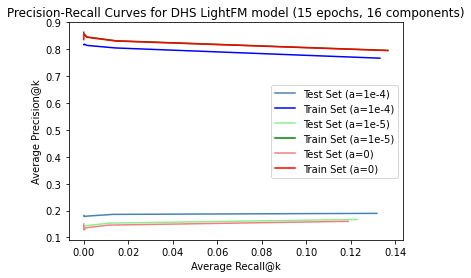

In [301]:
#Plot precision-recall curves for train and test data (15 epochs, 16 dimensions)
fig = plt.figure()
fig.patch.set_facecolor('white')
plt.plot(test_recall_e15_d16_reg0001, test_precision_e15_d16_reg0001, color='steelblue')
plt.plot(train_recall_e15_d16_reg0001, train_precision_e15_d16_reg0001, color='blue')
plt.plot(model_e15_d16_reg00001_test_recall, model_e15_d16_reg00001_test_precision, color='lightgreen')
plt.plot(model_e15_d16_reg00001_train_recall, model_e15_d16_reg00001_train_precision, color='green')
plt.plot(model_e15_d16_test_recall, model_e15_d16_test_precision, color='lightcoral')
plt.plot(model_e15_d16_train_recall, model_e15_d16_train_precision, color='red')
plt.xlabel('Average Recall@k')
plt.ylabel('Average Precision@k')
plt.legend(['Test Set (a=1e-4)', 'Train Set (a=1e-4)', 'Test Set (a=1e-5)', 'Train Set (a=1e-5)', 'Test Set (a=0)', 'Train Set (a=0)'], 
           loc='right')
plt.title('Precision-Recall Curves for DHS LightFM model (15 epochs, 16 components)')

Text(0.5, 1.0, 'Precision-Recall Curves for DHS LightFM models')

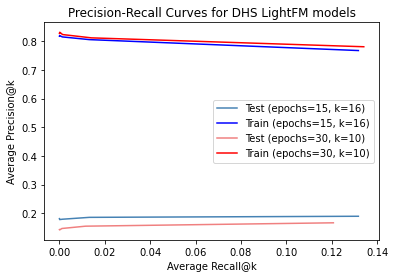

In [8]:
#Comparing e30_d10 model to e_15_d16 model
fig = plt.figure()
fig.patch.set_facecolor('white')
plt.plot(test_recall_e15_d16_reg0001, test_precision_e15_d16_reg0001, color='steelblue')
plt.plot(test_recall_e15_d16_reg0001, train_precision_e15_d16_reg0001, color='blue')
plt.plot(test_recall_e30_d10, test_precision_e30_d10, color='lightcoral')
plt.plot(train_recall_e30_d10, train_precision_e30_d10, color='red')
plt.xlabel('Average Recall@k')
plt.ylabel('Average Precision@k')
plt.legend(['Test (epochs=15, k=16)', 'Train (epochs=15, k=16)', 'Test (epochs=30, k=10)', 'Train (epochs=30, k=10)'], 
           loc='right')
plt.title('Precision-Recall Curves for DHS LightFM models')

In [306]:
rec_info = sample_recommendation(model_e15_d16_reg0001, data_e15_d16_reg0001, ['GM06990'], print_num=5)

Biosample: GM06990 (0)
   Number of Known DHSs: 82918

   Recommended DHS Locations:
      chr19:10251779-10252000, Component: Tissue invariant, Number of Samples: 719
      chr11:72112260-72112520, Component: Tissue invariant, Number of Samples: 717
      chr3:38164980-38165260, Component: Tissue invariant, Number of Samples: 724
      chr19:37779520-37779725, Component: Tissue invariant, Number of Samples: 725
      chr4:94207500-94207700, Component: Tissue invariant, Number of Samples: 715


In [303]:
comp_precision = []
comp_recall = []
for k in [1, 10, 100, 1000, 10000, 100000, 1000000, len(rec_info[0][0])]:
    p, r = component_precision(rec_info[0], 'Tissue invariant', k)
    comp_precision.append(p)
    comp_recall.append(r)

Text(0.5, 1.0, 'Lympoid Component PR Curve for DHS LightFM model (30 epochs, 10 components)')

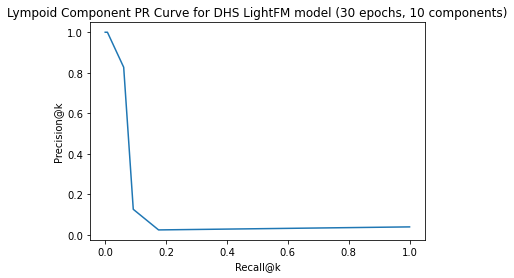

In [304]:
#Lymphoid component pr curve
plt.plot(comp_recall, comp_precision)
plt.xlabel('Recall@k')
plt.ylabel('Precision@k')
plt.title('Lympoid Component PR Curve for DHS LightFM model (30 epochs, 10 components)')

In [6]:
n_biosamples, n_DHSs = data_e15_d16_reg0001['test'].shape
test_precision_e15_d16_reg0001, test_recall_e15_d16_reg0001 = precision_recall_full(model_e15_d16_reg0001, data_e15_d16_reg0001['test'], [1, 10, 100, 1000, 10000, 100000, 1000000, n_DHSs])
train_precision_e15_d16_reg0001, train_recall_e15_d16_reg0001 = precision_recall_full(model_e15_d16_reg0001, data_e15_d16_reg0001['train'], [1, 10, 100, 1000, 10000, 100000, 1000000, n_DHSs])

Running precision and recall calculation setup
Calculating precision and recall
precision / recall@1 = 0.18144611186903137 / 1.3129730370739348e-05
precision / recall@10 = 0.17817189631650754 / 0.00012456782416461268
precision / recall@100 = 0.17937244201909958 / 0.0012690288152385329
precision / recall@1000 = 0.1859345156889495 / 0.01318230492197544
precision / recall@10000 = 0.1897316507503411 / 0.1316735431415578
precision / recall@100000 = 0.0952918826739427 / 0.5431645540551269
precision / recall@1000000 = 0.018762712141882677 / 0.928064932585605
precision / recall@3591898 = 0.005794269672474504 / 1.0
Running precision and recall calculation setup
Calculating precision and recall
precision / recall@1 = 0.8171896316507503 / 1.4441680102687852e-05
precision / recall@10 = 0.8193724420190996 / 0.00014598124450872365
precision / recall@100 = 0.8146111869031378 / 0.0014411915297099748
precision / recall@1000 = 0.8051582537517054 / 0.014209795101136687
precision / recall@10000 = 0.767087

In [7]:
test_precision_e15_d16_reg0001_full = [0.18144611186903137, 0.17817189631650754, 0.17937244201909958, 0.1859345156889495, 0.1897316507503411, 0.0952918826739427, 0.018762712141882677, 0.005794269672474504]
test_recall_e15_d16_reg0001_full = [1.3129730370739348e-05, 0.00012456782416461268, 0.0012690288152385329, 0.01318230492197544, 0.1316735431415578, 0.5431645540551269, 0.928064932585605, 1.0]

train_precision_e15_d16_reg0001_full = [0.8171896316507503, 0.8193724420190996, 0.8146111869031378, 0.8051582537517054, 0.7670870395634379, 0.3828691405184175, 0.07582572714870396, 0.023177077550453236]
train_recall_e15_d16_reg0001_full = [1.4441680102687852e-05, 0.00014598124450872365, 0.0014411915297099748, 0.014209795101136687, 0.13303056610257932, 0.5451171906242697, 0.9351381810744697, 1.0]

Text(0.5, 1.0, 'PR Curves for DHS LightFM model (15 epochs, 16 components, a=1e-4)\nk=[1, 10, 100, 1000, 10000, 100000, 1000000, 3591898]')

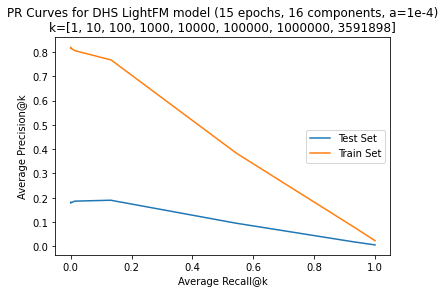

In [11]:
#Plot precision-recall curves for train and test data for k=[1, 10, 100, 1000, 10000, 100000, 1000000, n_DHSs]
fig = plt.figure()
fig.patch.set_facecolor('white')
plt.plot(test_recall_e15_d16_reg0001_full, test_precision_e15_d16_reg0001_full)
plt.plot(train_recall_e15_d16_reg0001_full, train_precision_e15_d16_reg0001_full)
plt.xlabel('Average Recall@k')
plt.ylabel('Average Precision@k')
plt.legend(['Test Set', 'Train Set'], loc='right')
plt.title('PR Curves for DHS LightFM model (15 epochs, 16 components, a=1e-4)\nk=[1, 10, 100, 1000, 10000, 100000, 1000000, 3591898]')

In [214]:
#comparing recommendation scores between known and unknown positives

n_biosamples, n_DHSs = data_e15_d16_reg0001['train'].shape
biosample_name = 'GM06990'
biosample = list(biosample_df[biosample_df['Biosample name']==biosample_name]['library order'])[0] - 1
known_positives = [i for i, dhs_pos in enumerate(list(dhs.T[biosample])) if dhs_pos == 1]

not_known_ind = list(set(np.arange(n_DHSs)) - set(known_positives))
# nki_series = pd.Series(not_known_ind)

known_ind = list(set(known_positives))
# ki_series = pd.Series(not_known_ind)

filtered_scores_nki = model_e15_d16_reg0001.predict(biosample, np.array(not_known_ind))
filtered_scores_ki = model_e15_d16_reg0001.predict(biosample, np.array(known_ind))

# filtered_top_DHSs = [np.argsort(-filtered_scores)][0]
# top_rec_DHSs = nki_series[filtered_top_DHSs]

In [271]:
# boxplot_dict = {'Known Positives': list(filtered_scores_ki), 'Not Known Positives': list(filtered_scores_nki)}
boxplot_list = [list(filtered_scores_ki), list(filtered_scores_nki)]

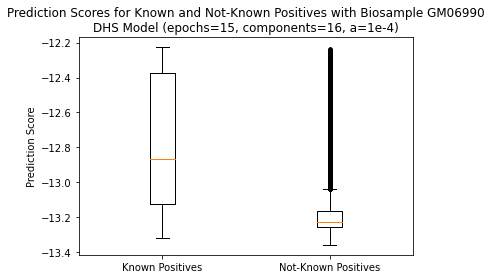

In [296]:
fig = plt.figure()
fig = fig.patch.set_facecolor('white')
fig = plt.boxplot(boxplot_list, sym='.')
fig = plt.xticks([1, 2], ['Known Positives', 'Not-Known Positives'])
fig = plt.ylabel('Prediction Score')
fig = plt.title('Prediction Scores for Known and Not-Known Positives with Biosample GM06990\nDHS Model (epochs=15, components=16, a=1e-4)')

**Adjusting learning rate for model 2 (k=16 components, epochs=15 a=0.0001) to 0.01**

In [4]:
#80/20 train test split to test precision values between train and test datasets
(train, test) = cross_validation.random_train_test_split(data_coo, test_percentage=0.2, random_state=None)
data_80_20 = {'train': train, 'test': test}
#creating model with L2 regularization set to 0.0001, k=16 components, learning rate of 0.01
model_e15_d16_reg0001_lr01 = LightFM(no_components=16, loss='warp', item_alpha=0.0001, user_alpha=0.0001, learning_rate=0.01)
#training model
model_e15_d16_reg0001_lr01.fit(data_80_20['train'], epochs=15, num_threads=2)

In [5]:
pickle_out_model = open('/home/ctrader/Hold/DHS/DHS_model_e15_d16_reg0001_lr01.pickle', 'wb')
pickle.dump(model_e15_d16_reg0001_lr01, pickle_out_model)
pickle_out_model.close()

pickle_out_data = open('/home/ctrader/Hold/DHS/DHS_data_e15_d16_reg0001_lr01.pickle', 'wb')
pickle.dump(data_80_20, pickle_out_data)
pickle_out_data.close()

In [152]:
pickle_in = open('/home/ctrader/Hold/DHS/DHS_model_e15_d16_reg0001_lr01.pickle', 'rb')
model_e15_d16_reg0001_lr01=pickle.load(pickle_in)

pickle_in = open('/home/ctrader/Hold/DHS/DHS_data_e15_d16_reg0001_lr01.pickle', 'rb')
data_e15_d16_reg0001_lr01=pickle.load(pickle_in)

In [3]:
user_b, user_e = model_e15_d16_reg0001_lr01.get_user_representations()
print(user_e)
item_b, item_e = model_e15_d16_reg0001_lr01.get_item_representations()
print(item_e)

[[-0.16483624  0.16577724  0.1487516  ...  0.15377332  0.16932388
  -0.13415691]
 [-0.17605893  0.18297732  0.15298566 ...  0.16534439  0.17861515
  -0.18949321]
 [-0.19358116  0.20060322  0.17726064 ...  0.18319112  0.20243977
  -0.15700097]
 ...
 [-0.1446564   0.16343474  0.12369475 ...  0.14484937  0.1692213
  -0.15347636]
 [-0.13999578  0.16867234  0.12543625 ...  0.1469745   0.16664428
  -0.16619278]
 [-0.13721704  0.16700096  0.12316039 ...  0.1465031   0.16648772
  -0.16539086]]
[[ 0.01439857 -0.01495687 -0.01542091 ... -0.01412861 -0.01575394
   0.01506215]
 [ 0.01298185 -0.01323263 -0.01387034 ... -0.01275708 -0.01401816
   0.01374683]
 [ 0.00753779 -0.00811703 -0.00795569 ... -0.00707912 -0.00780181
   0.00769207]
 ...
 [ 0.00956523 -0.00943432 -0.00995047 ... -0.00937949 -0.01020049
   0.01056642]
 [ 0.01068882 -0.01109402 -0.01093741 ... -0.01056392 -0.01216155
   0.01174503]
 [ 0.01299551 -0.0133113  -0.01299943 ... -0.01236849 -0.01450433
   0.01444672]]


In [199]:
#Precision and Recall @ k scores for DHS_model_e15_d16_reg0001_lr01
with open('/home/ctrader/AG/AugmentedGenomics/recommendersystems/lightfm/DHS/precision_recall_results/DHS_model_e15_d16_reg0001_lr01_test_precision_recall.txt') as f:
    test_precision_recall = f.readlines()
print(test_precision_recall)
print()
with open('/home/ctrader/AG/AugmentedGenomics/recommendersystems/lightfm/DHS/precision_recall_results/DHS_model_e15_d16_reg0001_lr01_train_precision_recall.txt') as f:
    train_precision_recall = f.readlines()
print(train_precision_recall)

['Test Precision@[1, 10, 100, 1000, 10000] = [0.1377899045020464, 0.16712141882673942, 0.17885402455661664, 0.18518144611186904, 0.18968472032742156] \n', 'Test Recall@[1, 10, 100, 1000, 10000] = [8.940846455499892e-06, 0.0001205295598499011, 0.0012850394768395505, 0.013166659244657191, 0.13170541530640847]']

['Train Precision@[1, 10, 100, 1000, 10000] = [0.8526603001364257, 0.8246930422919508, 0.8144884038199182, 0.8048690313778991, 0.7668226466575715] \n', 'Train Recall@[1, 10, 100, 1000, 10000] = [1.5271719948009334e-05, 0.00014491991052940125, 0.00143535723153781, 0.014179465160395737, 0.1329143617450964]']


In [203]:
test_precision_e15_d16_reg0001_lr01 = [0.1377899045020464, 0.16712141882673942, 0.17885402455661664, 0.18518144611186904, 0.18968472032742156]
test_recall_e15_d16_reg0001_lr01 = [8.940846455499892e-06, 0.0001205295598499011, 0.0012850394768395505, 0.013166659244657191, 0.13170541530640847]

train_precision_e15_d16_reg0001_lr01 = [0.8526603001364257, 0.8246930422919508, 0.8144884038199182, 0.8048690313778991, 0.7668226466575715]
train_recall_e15_d16_reg0001_lr01 = [1.5271719948009334e-05, 0.00014491991052940125, 0.00143535723153781, 0.014179465160395737, 0.1329143617450964]

Text(0.5, 1.0, 'Precision-Recall Curves for DHS LightFM model (15 epochs, 16 components)')

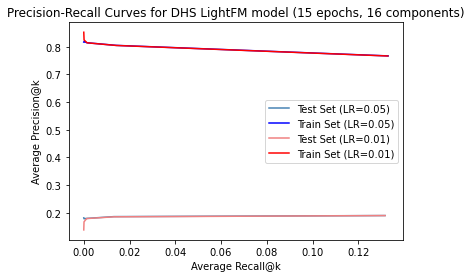

In [204]:
#Plot precision-recall curves for train and test data (15 epochs, 16 dimensions)
plt.plot(test_recall_e15_d16_reg0001, test_precision_e15_d16_reg0001, color='steelblue')
plt.plot(train_recall_e15_d16_reg0001, train_precision_e15_d16_reg0001, color='blue')
plt.plot(test_recall_e15_d16_reg0001_lr01, test_precision_e15_d16_reg0001_lr01, color='lightcoral')
plt.plot(train_recall_e15_d16_reg0001_lr01, train_precision_e15_d16_reg0001_lr01, color='red')
plt.xlabel('Average Recall@k')
plt.ylabel('Average Precision@k')
plt.legend(['Test Set (LR=0.05)', 'Train Set (LR=0.05)', 'Test Set (LR=0.01)', 'Train Set (LR=0.01)'], 
           loc='right')
plt.title('Precision-Recall Curves for DHS LightFM model (15 epochs, 16 components)')

**Training models for different epochs**

In [159]:
files = []
files.append('DHS_model_e5_d16_reg0001testprecision_recall.txt')
files.append('DHS_model_e5_d16_reg0001trainprecision_recall.txt')
files.append('DHS_model_e10_d16_reg0001testprecision_recall.txt')
files.append('DHS_model_e10_d16_reg0001trainprecision_recall.txt')
files.append('DHS_model_e15_d16_reg0001testprecision_recall.txt')
files.append('DHS_model_e15_d16_reg0001trainprecision_recall.txt')
files.append('DHS_model_e20_d16_reg0001testprecision_recall.txt')
files.append('DHS_model_e20_d16_reg0001trainprecision_recall.txt')
files.append('DHS_model_e25_d16_reg0001testprecision_recall.txt')
files.append('DHS_model_e25_d16_reg0001trainprecision_recall.txt')
files.append('DHS_model_e30_d16_reg0001testprecision_recall.txt')
files.append('DHS_model_e30_d16_reg0001trainprecision_recall.txt')
files.append('DHS_model_e40_d16_reg0001testprecision_recall.txt')
files.append('DHS_model_e40_d16_reg0001trainprecision_recall.txt')
files.append('DHS_model_e50_d16_reg0001testprecision_recall.txt')
files.append('DHS_model_e50_d16_reg0001trainprecision_recall.txt')
files.append('DHS_model_e75_d16_reg0001testprecision_recall.txt')
files.append('DHS_model_e75_d16_reg0001trainprecision_recall.txt')
files.append('DHS_model_e100_d16_reg0001testprecision_recall.txt')
files.append('DHS_model_e100_d16_reg0001trainprecision_recall.txt')

In [160]:
#Precision and Recall @ k scores for DHS_model_e_d16_reg0001_lr01
precision_values = []
recall_values = []
counter = 0
for file_name in files:
    file_path = os.path.join('/home/ctrader/AG/AugmentedGenomics/recommendersystems/lightfm/DHS/precision_recall_results/', file_name)
    with open(file_path, 'r') as f:
        for line in f:
            line = line.split('=')
            line = line[1].strip().strip('[').strip(']')
            line = line.split(', ')
            line = list(map(float, line))
            if counter % 2 == 0:
                precision_values.append(line)
            else:
                recall_values.append(line)
            counter+=1         

Text(0.5, 1.0, 'Precision-Recall Curves for DHS LightFM models (a=1e-4, k=16 components)')

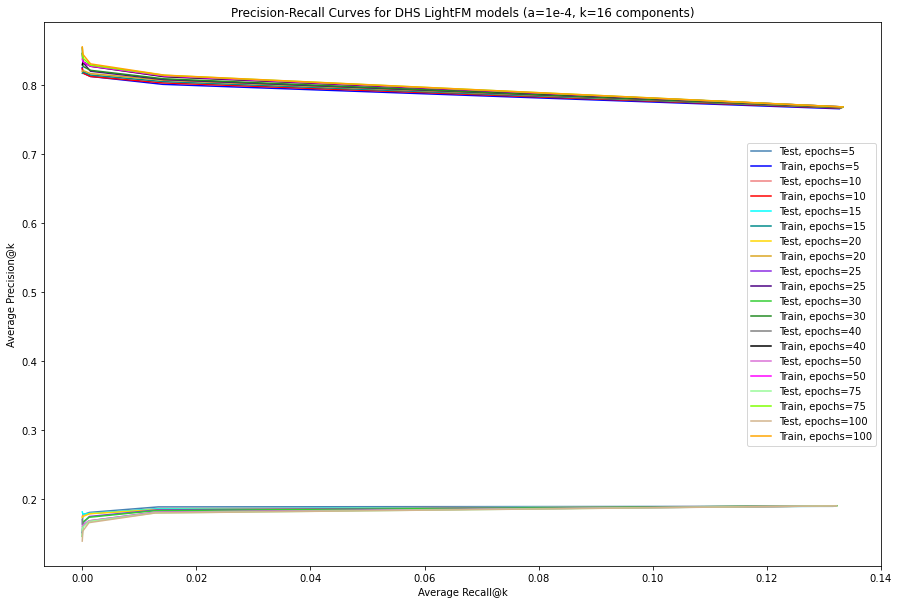

In [170]:
#Plot precision-recall curves for train and test data (15 epochs, 16 dimensions)
c = ['steelblue', 'blue', 'lightcoral', 'red', 'cyan', 'darkcyan', 'gold', 'goldenrod', 'blueviolet', 'indigo', 'limegreen', 'forestgreen', 'grey', 'black', 'orchid', 'magenta', 'palegreen', 'chartreuse', 'tan', 'orange']
l = ['Test, epochs=5', 'Train, epochs=5', 'Test, epochs=10', 'Train, epochs=10', 'Test, epochs=15', 'Train, epochs=15', 'Test, epochs=20', 'Train, epochs=20', 'Test, epochs=25', 'Train, epochs=25', 'Test, epochs=30', 'Train, epochs=30', 'Test, epochs=40', 'Train, epochs=40', 'Test, epochs=50', 'Train, epochs=50', 'Test, epochs=75', 'Train, epochs=75', 'Test, epochs=100', 'Train, epochs=100']
fig = plt.figure(figsize=(15,10))
fig.patch.set_facecolor('white')
for i in range(len(precision_values)):
    plt.plot(recall_values[i], precision_values[i], color=c[i])
plt.xlabel('Average Recall@k')
plt.ylabel('Average Precision@k')
plt.legend(l, loc='right')
plt.title('Precision-Recall Curves for DHS LightFM models (a=1e-4, k=16 components)')

**Adjusting alpha regularization values for model 2 (k=16 components, epochs=15) to 0.00001**

In [111]:
#80/20 train test split to test precision values between train and test datasets
(train, test) = cross_validation.random_train_test_split(data_coo, test_percentage=0.2, random_state=None)
data_80_20 = {'train': train, 'test': test}
#creating model with L2 regularization set to 0.001, k=16 components
model_e15_d16_reg00001 = LightFM(no_components=16, loss='warp', item_alpha=0.00001, user_alpha=0.00001)
#training model
model_e15_d16_reg00001.fit(data_80_20['train'], epochs=15, num_threads=2)

In [217]:
user_b, user_e = model_e15_d16_reg00001.get_user_representations()
print(user_e)
item_b, item_e = model_e15_d16_reg00001.get_item_representations()
print(item_e)

[[-2.0906634   1.8546653   1.9692941  ... -1.3520951   0.20131573
   0.8666315 ]
 [ 0.6466236   2.066677   -1.0889381  ...  2.4525106   1.3928869
  -0.01660642]
 [-1.9957765   1.4628907   1.2792798  ... -0.02385798  0.07691262
  -0.50173795]
 ...
 [ 1.1927788   3.1767805   0.68129855 ...  0.36804384  2.7848048
   0.21285807]
 [ 0.9045258   2.857363   -0.08097604 ...  0.10201646  5.2988853
  -0.07790955]
 [ 1.0142272   2.9209576  -0.08180873 ...  0.0838751   5.315526
  -0.19112782]]
[[ 0.03318062  0.08973543  0.17065954 ... -0.16512406  0.03641047
  -0.17259715]
 [ 0.15537748  0.04823514 -0.00691903 ... -0.00175932 -0.06660224
  -0.14679715]
 [-0.0933437  -0.08303365  0.13252145 ... -0.06879919 -0.1888858
   0.01975318]
 ...
 [ 0.12554476  0.07025028 -0.07974731 ... -0.00253858  0.02790248
   0.02964003]
 [ 0.15781777  0.07370334  0.09394893 ... -0.23880535 -0.07770683
   0.0022407 ]
 [ 0.08032778  0.0621774   0.10817247 ... -0.21860011 -0.11208315
  -0.03975179]]


In [115]:
pickle_out_model = open('/home/ctrader/Hold/DHS/DHS_model_e15_d16_reg00001.pickle', 'wb')
pickle.dump(model_e15_d16_reg00001, pickle_out_model)
pickle_out_model.close()

pickle_out_data = open('/home/ctrader/Hold/DHS/DHS_data_e15_d16_reg00001.pickle', 'wb')
pickle.dump(data_80_20, pickle_out_data)
pickle_out_data.close()

In [211]:
#Precision and Recall @ k scores for DHS_model_e15_d16_reg00001
with open('DHS_model_e15_d16_reg05_test_precision_recall.txt') as f:
    test_precision_recall = f.readlines()
print(test_precision_recall)
print()
with open('DHS_model_e15_d16_reg05_train_precision_recall.txt') as f:
    train_precision_recall = f.readlines()
print(train_precision_recall)

['Test Precision@[1, 10, 100, 1000, 10000] = [0.0, 0.0, 0.0004229195088676672, 0.0031596180081855394, 0.0403237380627558] \n', 'Test Recall@[1, 10, 100, 1000, 10000] = [0.0, 0.0, 1.252601081375641e-06, 0.00011743335744602837, 0.022337723366463093]']



FileNotFoundError: [Errno 2] No such file or directory: 'DHS_model_e15_d16_reg05_train_precision_recall.txt'

In [298]:
model_e15_d16_reg00001_test_precision = [0.1296043656207367, 0.13956343792633016, 0.1440518417462483, 0.15345702592087312, 0.16702046384720326]
model_e15_d16_reg00001_test_recall = [1.1073560697469647e-05, 0.00011351273372921383, 0.0011142584926762563, 0.011633033740440326, 0.12287782314369584]

model_e15_d16_reg00001_train_precision = [0.8635743519781719, 0.8536152796725786, 0.8460163710777626, 0.8318854024556616, 0.7959781718963165]
model_e15_d16_reg00001_train_recall = [1.4809866515884741e-05, 0.0001475213145611531, 0.0014715323307665357, 0.014467299278161039, 0.13673375677728258]

Text(0.5, 1.0, 'Precision-Recall Curves for DHS LightFM model (15 epochs, 16 components)')

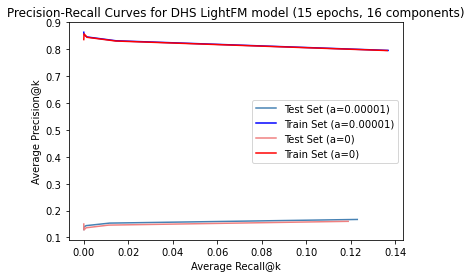

In [226]:
#Plot precision-recall curves for train and test data (15 epochs, 16 dimensions)
plt.plot(model_e15_d16_reg00001_test_recall, model_e15_d16_reg00001_test_precision, color='steelblue')
plt.plot(model_e15_d16_reg00001_train_recall, model_e15_d16_reg00001_train_precision, color='blue')
plt.plot(test_recall_list_top, test_precision_list_top, color='lightcoral')
plt.plot(train_recall_list_top, train_precision_list_top, color='red')
plt.xlabel('Average Recall@k')
plt.ylabel('Average Precision@k')
plt.legend(['Test Set (a=0.00001)', 'Train Set (a=0.00001)', 'Test Set (a=0)', 'Train Set (a=0)'], 
           loc='right')
plt.title('Precision-Recall Curves for DHS LightFM model (15 epochs, 16 components)')

**Function to recommend DHSs for a given biosample**

In [7]:
tsv_file = open("DHS_Index_and_Vocabulary_metadata.tsv")
df = pd.read_csv(tsv_file, delimiter="\t")
# print(df.head(20))

In [8]:
biosample_df = df[['library order', 'Biosample name']]

In [146]:
# print(biosample_df[biosample_df['library order']==1]['Biosample name'][0])
# print(biosample_df[biosample_df['Biosample name']=='GM06990']['library order'][0])

In [9]:
DHS_metadata = pd.read_table('DHS_Index_and_Vocabulary_hg38_WM20190703.txt.gz', header=None)

col_names = DHS_metadata.iloc[0]
DHS_metadata = DHS_metadata[1:]
DHS_metadata.columns = col_names
DHS_metadata = DHS_metadata.reset_index()
DHS_metadata[['identifier']] = DHS_metadata[['identifier']].astype(str)
DHS_metadata = DHS_metadata.drop(columns=['index'])

/home/ctrader/.conda/envs/lightfm/lib/python3.8/site-packages/IPython/core/interactiveshell.py:3441: DtypeWarning: Columns (1,2,3,4,5,6,7,8) have mixed types.Specify dtype option on import or set low_memory=False.
  exec(code_obj, self.user_global_ns, self.user_ns)


In [148]:
#This code is for reordering the DHS_Index_and_Vocabulary_hg38_WM20190703 file. However, I believe the
#ordering here is correct, the order of the individual biosample signal files needs to be changed. 
#See https://zenodo.org/record/3752359#.YW7vUdnMKWA

# DHS_metadata[['identifier']] = DHS_metadata[['identifier']].astype(str)
# DHS_metadata[['id1', 'id2']] = DHS_metadata['identifier'].str.split('.', 1, expand=True)
# DHS_metadata['id1']=DHS_metadata['id1'].mask(DHS_metadata['id1'] == 'X', '23')
# DHS_metadata['id1']=DHS_metadata['id1'].mask(DHS_metadata['id1'] == 'Y', '24')
# DHS_metadata['id1_2'] = DHS_metadata[['id1','id2']].agg('.'.join, axis=1)
# DHS_metadata[['id1_2']] = DHS_metadata[['id1_2']].apply(pd.to_numeric)
# DHS_metadata = DHS_metadata.sort_values(by=['id1_2'], ignore_index=True)
# DHS_metadata = DHS_metadata.reset_index()

In [149]:
# DHS_metadata[DHS_metadata['seqname']=='chr2']


In [150]:
#chr6:43383800-43384008
# seq_mask = DHS_metadata['seqname']=='chr6'
# start_mask = DHS_metadata['start']==43383800
# end_mask = DHS_metadata['end']==43384008
# DHS_metadata[seq_mask & start_mask & end_mask]

In [151]:
# DHS_metadata.iloc[2802885-1]


In [ ]:
# biosample = list(biosample_df[biosample_df['Biosample name']=='GM06990']['library order'])[0] - 1
# print(biosample)

In [ ]:
# x = dhs.T[0]
# # x
# type(x)

In [152]:
# comp_list = DHS_metadata.reset_index()
# comp_list = comp_list['component']

# comp_list[i_access]

In [153]:
# DHS_metadata

In [4]:
#function to recommend DHSs for a given biosample. Takes in the model, data, and a list of
#biosamples for DHSs to be recommend for. For each biosample, prints out known associated DHSs
#and a list of recommended DHSs. Function modeled after tutorial 3, 'Recommendation Systems
#- Learn Python for Data Science' on LightFM github. 

def sample_recommendation(model, data, biosamples, print_num=3): #, full_data=gd_coo
    
    #number of biosamples and DHSs in dataset
    n_biosamples, n_DHSs = data['train'].shape
    return_list = []
    #generate DHS recommendations for each biosample
    for biosample_name in biosamples:
        if isinstance(biosample_name, str):
            biosample = list(biosample_df[biosample_df['Biosample name']==biosample_name]['library order'])[0] - 1
        else:
            biosample = biosample_name
        
        #DHSs known to relate to the biosample
        #indices
        known_positives = [i for i, dhs_pos in enumerate(list(dhs.T[biosample])) if dhs_pos == 1]
#         print(known_positives.index(737810))
        
        #filter out known positives from what will be recommended
        not_known_ind = list(set(np.arange(n_DHSs)) - set(known_positives))
        nki_series = pd.Series(not_known_ind)
        
        #DHSs model predicts that relate to biosample
#         scores = model.predict(biosample, np.arange(n_DHSs))
        filtered_scores = model.predict(biosample, np.array(not_known_ind))

        #rank from most related to least
#         top_DHSs = [np.argsort(-scores)][0]
        #not DHS indices
        filtered_top_DHSs = [np.argsort(-filtered_scores)][0]
        top_rec_DHSs = nki_series[filtered_top_DHSs]
        
#         print(list(top_rec_DHSs).index(0))
#         filtered_DHSs = [dhs_ind for dhs_ind in top_DHSs if dhs_ind not in set(known_positives)]
#         filtered_DHSs = set(top_DHSs)-set(known_positives)
        metadata = DHS_metadata.reset_index()
        comp_ser = metadata['component']
        comp_rec = list(comp_ser[top_rec_DHSs])
#         print(comp_rec[0:5])
        chrom_ser = metadata['seqname']
        chrom_rec = list(chrom_ser[top_rec_DHSs])
        start_ser = metadata['start']
        start_rec = list(start_ser[top_rec_DHSs])
        end_ser = metadata['end']
        end_rec = list(end_ser[top_rec_DHSs])
        numsamples_ser = metadata['numsamples']
        numsamples_rec = list(numsamples_ser[top_rec_DHSs])
        
        
        
        
        #print results
        print('Biosample: %s (%s)' %(biosample_name, str(biosample)))
        print('   Number of Known DHSs: %s' %(len(known_positives)))
        
        print()
        print('   Recommended DHS Locations:')
        count = 0
        total_count = 0
        return_biosample = []
        return_biosample.append(comp_rec)
        return_biosample.append(chrom_rec)
        return_biosample.append(start_rec)
        return_biosample.append(end_rec)
        return_biosample.append(numsamples_rec)
        return_biosample.append(list(top_rec_DHSs))
        return_list.append(return_biosample)
#         coord_list = []
#         comp_list = []
#         sample_num_list = []
        
        for i in range(print_num):
#             DHS = not_known_ind[filtered_DHS]
#             total_count+=1
#             if DHS not in known_positives:
#             DHS_metadata_num = DHS #+1
            chrom = chrom_rec[i]
            start = start_rec[i]
            end = end_rec[i]
            component = comp_rec[i]
            num_samples = numsamples_rec[i]
#             num_samples = DHS_metadata.iloc[DHS_metadata_num]['numsamples']
#             if count < print_num:
            print('      %s:%s-%s, Component: %s, Number of Samples: %s' %(chrom, start, end, component, num_samples))
#             count += 1
#             coord_list.append(str(chrom)+':'+str(start)+'-'+str(end))
#             comp_list.append(component)
#             sample_num_list.append(num_samples)
#             if count == recommend_num:
        return return_list

In [281]:
rec_info = sample_recommendation(DHS_model30, DHS_data30, ['GM06990'], print_num=5)

Biosample: GM06990 (0)
   Number of Known DHSs: 82918

   Recommended DHS Locations:
      chr6:43383800-43384008, Component: Lymphoid, Number of Samples: 229
      chr22:20463632-20463840, Component: Lymphoid, Number of Samples: 77
      chr2:64283739-64283940, Component: Lymphoid, Number of Samples: 74
      chr15:89017645-89017840, Component: Tissue invariant, Number of Samples: 571
      chr1:225467176-225467360, Component: Lymphoid, Number of Samples: 115


In [259]:
rec_info = sample_recommendation(model_e15_d16_reg0001, data_e15_d16_reg0001, ['GM06990'], print_num=5)

Biosample: GM06990 (0)
   Number of Known DHSs: 82918

   Recommended DHS Locations:
      chr19:10251779-10252000, Component: Tissue invariant, Number of Samples: 719
      chr11:72112260-72112520, Component: Tissue invariant, Number of Samples: 717
      chr3:38164980-38165260, Component: Tissue invariant, Number of Samples: 724
      chr19:37779520-37779725, Component: Tissue invariant, Number of Samples: 725
      chr4:94207500-94207700, Component: Tissue invariant, Number of Samples: 715


In [ ]:
#Desired output (correct DHS_metadata indexing)

# Biosample: GM06990 (0)
#    Number of Known DHSs: 82918

#    Recommended DHS Locations:
#       chr6:43383800-43384008, Component: Lymphoid, Number of Samples: 229
#       chr22:20463632-20463840, Component: Lymphoid, Number of Samples: 77
#       chr2:64283739-64283940, Component: Lymphoid, Number of Samples: 74
#       chr15:89017645-89017840, Component: Tissue invariant, Number of Samples: 571
#       chr1:225467176-225467360, Component: Lymphoid, Number of Samples: 115

**Function to determine if a dhs is recommended to a biosample because it has other DHSs near by**

In [173]:
one_side = []
both_sides = []
k_vals = [1, 2, 3, 4, 5, 10, 20, 30, 40, 50, 75, 100, 500, 1000, 10000, 100000, 1000000, len(rec_info[0][5])]
for k in k_vals:
    one, both = dhs_nearby(rec_info[0][5], 'GM06990', k)
    one_side.append(one)
    both_sides.append(both)

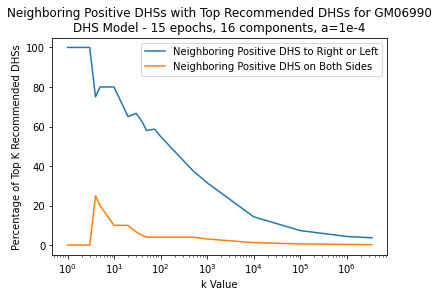

In [176]:
fig = plt.figure()

fig.patch.set_facecolor('white')
plt.plot(k_vals, one_side)
plt.plot(k_vals, both_sides)
plt.xscale('log')
plt.xlabel('k Value')
plt.ylabel('Percentage of Top K Recommended DHSs')
plt.legend(['Neighboring Positive DHS to Right or Left', 'Neighboring Positive DHS on Both Sides'])
fig = plt.title('Neighboring Positive DHSs with Top Recommended DHSs for GM06990\nDHS Model - 15 epochs, 16 components, a=1e-4')

In [48]:
dhs_array = dhs.to_numpy()

3591898

In [79]:
def dhs_nearby(dhs_ids, biosample_name, k):
    biosample = list(biosample_df[biosample_df['Biosample name']==biosample_name]['library order'])[0] - 1
    #ordered (by recommendation order) DHS ids
    dhs_ids = np.array(dhs_ids)
    #dhs to the right of recommended dhs
    dhs_right = dhs_ids[:]+1
    #dhs to the left of recommended dhs
    dhs_left = dhs_ids[:]-1
    
    n_biosamples, n_dhs = dhs_array.shape
    
    #removing dhss that don't exist
    dhs_right = np.delete(dhs_right, np.where(dhs_right == n_dhs))
    dhs_left = np.delete(dhs_left, np.where(dhs_left == -1))
    
    #determining presence/absense of dhss to right and left of recommended dhs
    right = dhs_array[biosample, dhs_right] 
    left = dhs_array[biosample, dhs_left]
    total = right + left
    #top k recs
    total = total[:k]
    both_sides = np.count_nonzero(total == 2)/k * 100
    one_side = np.count_nonzero(total == 1)/k * 100
#     print('Percent of recommended DHSs with a known positive DHS to right or left: ' + str(one_side) + '%')
#     print('Percent of recommended DHSs with a known positive DHS to right and left: ' + str(both_sides) + '%')
    return one_side, both_sides

dhs_nearby(rec_info[0][5], 'GM06990', 20)

(40.0, 10.0)

**Function to determine is a dhs is recommended to a biosample because it exists in similar biosamplse**

In [266]:
pos_percent_list = []
k_vals = [1, 2, 3, 4, 5, 10, 20, 30, 40, 50, 75, 100, 500, 1000, 10000, 100000, 1000000, len(rec_info[0][5])]
for k in k_vals:
    pos_percent = similar_biosamples(rec_info[0][5], 'GM06990', k)
    pos_percent_list.append(pos_percent)

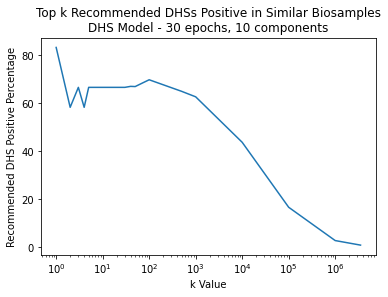

In [267]:
fig = plt.figure()
fig.patch.set_facecolor('white')
plt.plot(k_vals, pos_percent_list)
plt.xscale('log')
plt.xlabel('k Value')
plt.ylabel('Recommended DHS Positive Percentage')
fig = plt.title('Top k Recommended DHSs Positive in Similar Biosamples\nDHS Model - 30 epochs, 10 components') #

In [262]:
def similar_biosamples(dhs_ids, biosample_name, k):
    dhs_ids = np.array(dhs_ids)
    biosample = list(biosample_df[biosample_df['Biosample name']==biosample_name]['library order'])[0] - 1
    sample_type = df.iloc[biosample]['Description ']
    similar_samples = np.array(list(df[df['Description ']=='Lymphoblastoid']['library order']))-1
    similar_samples = np.delete(similar_samples, np.where(similar_samples == biosample))
#     similar_samples = similar_samples + 10
    similar_samples_dhs = dhs_array[similar_samples, :]
    similar_samples_recs = similar_samples_dhs[:, dhs_ids[:k]]
#     print(similar_samples_recs)
    count = np.count_nonzero(similar_samples_recs == 1)
    rows, col = similar_samples_recs.shape
    total_size = rows * col
    positive_percent = count / total_size * 100
    return positive_percent

similar_biosamples(rec_info[0][5], 'GM06990', 1)

100.0

**Function to calculate component precision values**

In [274]:
#takes in recommendation info for a single biosample and the component to calculate precision values for.
#Returns precision values for this component
def component_precision(rec_info, target_comp, k=1):
    comps = rec_info[0]
    total_of_comp = comps.count(target_comp)
    count = comps[0:k].count(target_comp)
    precision = count/k
    recall = count/total_of_comp
    return precision, recall

**Created function to calculate precision and recall for train and test datasets**

In [2]:
#rewriting precision function 2.0
def precision_recall_setup(model, data):
    """
    Function to set up precision and recall calculations. Takes in model and data. Returns a Numpy array of DHS
    recommendations for each biosample and a Numpy array of known positive interatcions between each biosample and
    DHS. 
    """
    data_array = data.toarray()
    recs = []
    kp = []
    
    for i in range(n_biosamples): #n_biosamples
        biosample_rec_scores = model.predict((i), np.arange(n_DHSs))
        recs.append(np.argsort(-biosample_rec_scores))
        kp.append(set(np.where(data_array[i] == 1)[0]))
    recs = np.array(recs)
    kp = np.array(kp)
    return recs, kp


def precision_recall_calc(recs, kp, k_vals):
    """
    Function to calculate precision recall values. Takes in a Numpy array of DHS recommendations for each 
    biosample, a Numpy array of known positive interatcions between each biosample and DHS, and a list of
    k values. Returns a list of the average precision values across all biosamples and a list of the 
    average recall values across all biosamples
    """
    precision_list = []
    recall_list = []
    for k in k_vals:
        top_k_recs = []
        for i in range(n_biosamples): #n_biosamples
            top_k_recs.append(set(recs[i, :k]))
        top_k_recs = np.array(top_k_recs)
        kp_topk = kp-top_k_recs
        topk_kp = top_k_recs-kp
        recs_len = np.repeat(k, n_biosamples) #n_biosamples
        fn = []
        fp = []
        for i in range(n_biosamples): #n_biosamples
            fn.append(len(kp_topk[i]))
            fp.append(len(topk_kp[i]))
        fn = np.array(fn)
        fp = np.array(fp)
        tp = recs_len - fp
        precision = tp / (tp + fp)
        recall = tp / (tp + fn)
        precision_list.append(np.average(precision))
        recall_list.append(np.average(recall))
        print('precision / recall@%s = %s / %s' %(k, np.average(precision), np.average(recall)))
    return precision_list, recall_list

def precision_recall_full(model, data, k_vals):
    """
    Full precision recall calculation function. Takes in model, data, and a list of k values. Returns a list of 
    the average precision values across all biosamples and a list of the average recall values across all biosamples.
    """
    print('Running precision and recall calculation setup')
    n_biosamples, n_DHSs = data.shape
    recs, kp = precision_recall_setup(model, data)
    print('Calculating precision and recall')
    precision, recall = precision_recall_calc(recs, kp, k_vals)
    return precision, recall

In [117]:
precision, recall = precision_recall_full(DHS_model30, DHS_data30['test'], [1, 10, 100, 1000, 10000])

In [5]:
#output all 0s when we start recommending for millions of pairs
import time
t = time.time()
biosamples_to_rec = np.repeat(np.arange(n_biosamples), n_DHSs)
DHSs_to_rec = np.tile(np.arange(n_DHSs), n_biosamples)
recs = DHS_model30.predict(biosamples_to_rec, DHSs_to_rec)
recs1 = recs.reshape((n_biosamples, n_DHSs))
print(time.time()-t)

79.76768016815186


In [75]:
x = np.arange(3)
np.tile(x, 2)
# print(type(DHSs_to_rec))

DHS_model30.predict(np.tile(np.arange(733), 30000), np.tile(np.arange(733), 30000))

array([ -89.06101, -100.68584,  -93.20314, ...,  -87.55253, -102.44978,
       -104.71145], dtype=float32)

In [26]:
GM06990_signal

,name,size,covered,sum,mean0,mean
0,1.10011,60,60,0.165045,0.002751,0.002751
1,1.10021,172,172,1.419380,0.008252,0.008252
2,1.10025,74,74,0.000000,0.000000,0.000000
3,1.10027,112,112,0.000000,0.000000,0.000000
4,1.1003,131,131,3.317400,0.025324,0.025324
...,...,...,...,...,...,...
3591893,Y.994281,179,179,0.000000,0.000000,0.000000
3591894,Y.994286,116,116,0.000000,0.000000,0.000000
3591895,Y.994292,227,227,0.000000,0.000000,0.000000
3591896,Y.994297,140,140,0.000000,0.000000,0.000000


**Function to find DHS specific signal values for DHS recs**

In [285]:
#Takes in recommended DHS indices and the signal data from a single biosample. Returns the average biosample signal
#across each recommended DHS and the average signal of all biosamples at each recommended DHS. 
def signal_values(dhs, signal_data):
    #Average biosample signal across each recommended DHS
    mean_signal_sample_series = pd.Series(signal_data['mean'])
    mean_signal_sample = mean_signal_sample_series[dhs]
    #Average signal of all biosamples at each recommended DHS
    mean_signal_DHS_series = pd.Series(DHS_metadata['mean_signal'])
    mean_signal_DHS = mean_signal_DHS_series[dhs]
    return list(mean_signal_sample), list(mean_signal_DHS)

mean_GM06990_signal, mean_DHS_signal = signal_values(rec_info[0][5], GM06990_signal)

In [288]:
print(mean_GM06990_signal[0:5])
# print()
print(mean_DHS_signal[0:5])
print(rec_info[0][0][0:5])

# print(DHS_metadata.iloc[2802884])
# print()
# print(GM06990_signal.iloc[2802884])

[2.17542, 0.421499, 0.18508, 1.34194, 2.39674]
[5.00350047161572, 1.59121971428571, 1.20959101351351, 2.12448843782837, 4.62136891304348]
['Lymphoid', 'Lymphoid', 'Lymphoid', 'Tissue invariant', 'Lymphoid']


**Ensuring that the precision-recall function created matches the precision/recall@k functions created by LightFM**

In [48]:
#makes sure the function works correctly
test_dense30 = DHS_data30['test'].todense()
test_precision_e30_d10, test_recall_e30_d10 = precision_recall(test_dense30, DHS_model30)

k = 1
0 / 733 biosamples done
100 / 733 biosamples done
200 / 733 biosamples done
300 / 733 biosamples done
400 / 733 biosamples done
500 / 733 biosamples done
600 / 733 biosamples done
700 / 733 biosamples done
precision@1 = 0.1432469304229195
recall@1 = 1.0259158846487058e-05
k = 10
0 / 733 biosamples done
100 / 733 biosamples done
200 / 733 biosamples done
300 / 733 biosamples done
400 / 733 biosamples done
500 / 733 biosamples done
600 / 733 biosamples done
700 / 733 biosamples done
precision@10 = 0.1421555252387449
recall@10 = 0.00010940640060583263
k = 100
0 / 733 biosamples done
100 / 733 biosamples done
200 / 733 biosamples done
300 / 733 biosamples done
400 / 733 biosamples done
500 / 733 biosamples done
600 / 733 biosamples done
700 / 733 biosamples done
precision@100 = 0.1471487039563438
recall@100 = 0.001110413940486401
k = 1000
0 / 733 biosamples done
100 / 733 biosamples done
200 / 733 biosamples done
300 / 733 biosamples done
400 / 733 biosamples done
500 / 733 biosample

**Checking precision values when sampling random DHSs**

In [18]:
#Precision for random recs
from random import sample
precision_list = []
for k in [1, 10, 100, 1000, 10000]:
    print(k)
    num = []
    for biosample in range(733):
        known_pos = [i for i, dhs_pos in enumerate(np.squeeze(np.asarray(train_dense[biosample]))) if dhs_pos == 1]
        rand_list = sample(range(0, n_dhs), k)
        rand_in_known = len([i for i in known_pos if i in rand_list])
        num.append(rand_in_known)
            
    num = np.array(num)
    precision = (num/k).mean()
    print(precision)
    precision_list.append(precision)

1


KeyboardInterrupt: 

In [ ]:
# measure precision/recall @ k for k=1:50
# test_precision = []
# test_recall = []
# train_precision = []
# train_recall = []

# for i in [1, 10, 100, 1000, 10000]:
#     test_precision.append(precision_at_k(model30_d1, data['test'], k=i).mean())
#     print('i')
#     test_recall.append(recall_at_k(model30, data['test'], k=i).mean())
#     train_precision.append(precision_at_k(model30, data['train'], k=i).mean())
#     train_recall.append(recall_at_k(model30, data['train'], k=i).mean())
#     print("k=" + i + " Finished")

In [42]:
# #Function for calculating precision and recall
# def precision_recall(dense, model, k_vals=[1, 10, 100, 1000, 10000]):
#     precision_list_top = []
#     recall_list_top = []
#     for k in k_vals:
#         print('k = ' + str(k))
#         num = []
#         n_known_pos = []
#         for biosample in range(733):
#             if biosample % 100 == 0:
#                 print(biosample, '/', n_biosamples, 'biosamples done')
#             scores = model.predict(biosample, np.arange(n_dhs)) 
#             top_DHSs = [np.argsort(-scores)][0][0:k]
#             known_pos = [i for i, dhs_pos in enumerate(np.squeeze(np.asarray(dense[biosample]))) if dhs_pos == 1]
#             top_in_known = len([i for i in known_pos if i in top_DHSs])
#             num.append(top_in_known)
#             n_known_pos.append(len(known_pos))
            
#         num = np.array(num)
#         precision = (num/k).mean()
#         recall = (num/n_known_pos).mean()
#         print('precision@%s = %s' %(k, precision))
#         print('recall@%s = %s' %(k, recall))
#         precision_list_top.append(precision)
#         recall_list_top.append(recall)
#     return precision_list_top, recall_list_top